### Exercise 1

Take an arbitrary DNA sequence from NCBI (National Center for Biotechnology Information), between 1000 and 3000
nucleotides (letters).

Sequence used: *Porcine circovirus 1*, complete genome (NCBI NC_001792.2, 1,758 nt). Circoviruses have one of the
smallest known viral genomes: a single circular DNA molecule, so the sequence has no real start or end.

In [1]:
import math
import re
from collections import Counter

import matplotlib.pyplot as plt


def read_fasta(path):
    with open(path) as f:
        lines = f.read().splitlines()
    return lines[0][1:], "".join(l.strip() for l in lines[1:]).upper()


header, dna = read_fasta("pcv1.fasta")
counts = Counter(dna)

print(header)
print(f"Length = {len(dna):,} nucleotides")
print("Composition: " + ", ".join(f"{b} = {counts[b]} ({counts[b] / len(dna):.1%})" for b in "ACGT"))
print(f"GC content = {(counts['G'] + counts['C']) / len(dna):.1%}\n")
for i in range(0, 180, 60):
    print(f"{i + 1:>5}  {dna[i:i + 60]}")
print("  ...")

NC_001792.2 Porcine circovirus 1, complete genome
Length = 1,758 nucleotides
Composition: A = 432 (24.6%), C = 344 (19.6%), G = 506 (28.8%), T = 476 (27.1%)
GC content = 48.4%

    1  GTAGTATTACCAGCGCACTTCGGCAGCGGCAGCACCTCGGCAGCGTCAGTGAAAATGCCA
   61  AGCAAGAAAAGCGGCCCGCAACCCCATAAGAGGTGGGTGTTCACCCTTAATAATCCTTCC
  121  GAGGAGGAGAAAAACAAAATACGGGAGCTTCCAATCTCCCTTTTTGATTATTTTGTTTGC
  ...


### Exercise 2

Use restriction enzymes (name, recognition sequence, cleavage site).

A restriction enzyme (restriction endonuclease) recognises a short, specific DNA sequence - the recognition site - and
cuts both strands of the DNA there. Most of the classic (type II) enzymes recognise palindromic sites: the site reads the
same on both strands (5'->3'), e.g. EcoRI `GAATTC` / `CTTAAG` read backwards. The cleavage site is written with a `^`
in the recognition sequence: EcoRI = `G^AATTC` cuts between G and A on the top strand, and (because the site is a palindrome)
at the same place on the bottom strand read 5'->3':

```
   EcoRI  G^AATTC              5' ...G   AATTC... 3'        sticky ends with a 5' overhang (AATT)
          CTTAA^G     ->       3' ...CTTAA   G... 5'

   SmaI   CCC^GGG              5' ...CCC   GGG... 3'        blunt ends (cut in the middle of the site)
          GGG^CCC     ->       3' ...GGG   CCC... 5'

   PstI   CTGCA^G              5' ...CTGCA   G... 3'        sticky ends with a 3' overhang (TGCA)
          G^ACGTC     ->       3' ...G   ACGTC... 5'
```

Some enzymes accept any base at some positions of the site; these are written with the IUPAC codes
(`N` = any base, `R` = A/G, `Y` = C/T, `W` = A/T, `S` = C/G, ...). For example HinfI = `G^ANTC` cuts `GAATC`, `GACTC`,
`GAGTC` and `GATTC`.

#### The enzymes used

| Enzyme | Source organism | Recognition site | Cut | Ends |
|:--|:--|:-:|:-:|:--|
| EcoRI | *Escherichia coli* RY13 | `GAATTC` | `G^AATTC` | 5' overhang |
| BamHI | *Bacillus amyloliquefaciens* H | `GGATCC` | `G^GATCC` | 5' overhang |
| HindIII | *Haemophilus influenzae* Rd | `AAGCTT` | `A^AGCTT` | 5' overhang |
| PstI | *Providencia stuartii* | `CTGCAG` | `CTGCA^G` | 3' overhang |
| KpnI | *Klebsiella pneumoniae* | `GGTACC` | `GGTAC^C` | 3' overhang |
| PvuII | *Proteus vulgaris* | `CAGCTG` | `CAG^CTG` | blunt |
| TaqI | *Thermus aquaticus* | `TCGA` | `T^CGA` | 5' overhang |
| MspI | *Moraxella* sp. | `CCGG` | `C^CGG` | 5' overhang |
| AluI | *Arthrobacter luteus* | `AGCT` | `AG^CT` | blunt |
| HaeIII | *Haemophilus aegyptius* | `GGCC` | `GG^CC` | blunt |
| HinfI | *Haemophilus influenzae* Rf | `GANTC` | `G^ANTC` | 5' overhang |

The table of the program (below) is built from the recognition sequence with `^` only: the recognised sequence, the cut
offset, the bottom-strand cut and the type of ends are all computed from it.

In [2]:
ENZYMES = {
    "EcoRI": "G^AATTC",
    "BamHI": "G^GATCC",
    "HindIII": "A^AGCTT",
    "PstI": "CTGCA^G",
    "KpnI": "GGTAC^C",
    "PvuII": "CAG^CTG",
    "TaqI": "T^CGA",
    "MspI": "C^CGG",
    "AluI": "AG^CT",
    "HaeIII": "GG^CC",
    "HinfI": "G^ANTC",
}

IUPAC = {"A": "A", "C": "C", "G": "G", "T": "T", "R": "AG", "Y": "CT", "S": "CG", "W": "AT", "K": "GT",
         "M": "AC", "B": "CGT", "D": "AGT", "H": "ACT", "V": "ACG", "N": "ACGT"}
IUPAC_COMPLEMENT = str.maketrans("ACGTRYSWKMBDHVN", "TGCAYRSWMKVHDBN")


def reverse_complement(s):
    return s.translate(IUPAC_COMPLEMENT)[::-1]


def parse_site(site):
    # G^AATTC -> GAATTC, cut = 1
    recseq = site.replace("^", "").upper()
    cut = site.index("^")
    if any(b not in IUPAC for b in recseq):
        raise ValueError(f"unknown base in {site}")
    if recseq != reverse_complement(recseq):
        raise ValueError(f"{site} is not palindromic; only palindromic (type II) sites are supported")
    return recseq, cut


def ends_type(recseq, cut):
    # overhang = len - 2*cut
    overhang = len(recseq) - 2 * cut
    if overhang == 0:
        return "blunt"
    seq = recseq[min(cut, len(recseq) - cut):max(cut, len(recseq) - cut)]
    return f"5' overhang {seq}" if overhang > 0 else f"3' overhang {seq}"


def strands(recseq, cut):
    bottom = recseq.translate(IUPAC_COMPLEMENT)
    c = len(recseq) - cut
    return recseq[:cut] + "^" + recseq[cut:], bottom[:c] + "^" + bottom[c:]


print(f"{'Enzyme':<8} | {'Recognised':<10} | {'Cut after':>9} | {'Top strand':<10} | {'Bottom (3->5)':<13} | Ends")
print("-" * 78)
for name, site in ENZYMES.items():
    recseq, cut = parse_site(site)
    top, bottom = strands(recseq, cut)
    print(f"{name:<8} | {recseq:<10} | {cut:>9} | {top:<10} | {bottom:<13} | {ends_type(recseq, cut)}")

Enzyme   | Recognised | Cut after | Top strand | Bottom (3->5) | Ends
------------------------------------------------------------------------------
EcoRI    | GAATTC     |         1 | G^AATTC    | CTTAA^G       | 5' overhang AATT
BamHI    | GGATCC     |         1 | G^GATCC    | CCTAG^G       | 5' overhang GATC
HindIII  | AAGCTT     |         1 | A^AGCTT    | TTCGA^A       | 5' overhang AGCT
PstI     | CTGCAG     |         5 | CTGCA^G    | G^ACGTC       | 3' overhang TGCA
KpnI     | GGTACC     |         5 | GGTAC^C    | C^CATGG       | 3' overhang GTAC
PvuII    | CAGCTG     |         3 | CAG^CTG    | GTC^GAC       | blunt
TaqI     | TCGA       |         1 | T^CGA      | AGC^T         | 5' overhang CG
MspI     | CCGG       |         1 | C^CGG      | GGC^C         | 5' overhang CG
AluI     | AGCT       |         2 | AG^CT      | TC^GA         | blunt
HaeIII   | GGCC       |         2 | GG^CC      | CC^GG         | blunt
HinfI    | GANTC      |         1 | G^ANTC     | CTNA^G        | 5' 

#### The digestion program

Input: the recognition sequence of each enzyme (with `^` at the cleavage site) and the DNA sequence to be digested.
Output: the number of cleavages of each enzyme, the cleavage positions, the fragments and their lengths, and the
simulated electrophoresis gel.

1. The recognition sequence is turned into a regular expression (every IUPAC code becomes a character class,
   e.g. `GANTC` -> `GA[ACGT]TC`). It is used inside a look-ahead `(?=...)`, so that overlapping sites are also found
   (e.g. `GGCCGGCC` contains two HaeIII sites that share bases).
2. Every match at position $p$ gives a cut at $p + \text{cut}$ - the cleavage position is given as the number of the
   last base before the cut (1-based), i.e. the enzyme cuts between base $p+\text{cut}$ and base $p+\text{cut}+1$.
3. The fragments are the pieces between consecutive cuts:
   - a linear molecule with $k$ cuts gives $k + 1$ fragments (the two ends are free);
   - a circular molecule with $k$ cuts gives $k$ fragments - the last fragment goes over the end of the sequence and
     continues at the start. For a circle the sequence is searched as `dna + dna[:len(site) - 1]` so that a site lying
     across the "end" of the sequence is not missed.

The fragment length is the length of the double-stranded piece measured on the top strand (the small overhangs are ignored,
as is usual for restriction maps).

In [3]:
def site_regex(recseq):
    return re.compile("(?=(" + "".join(b if len(IUPAC[b]) == 1 else f"[{IUPAC[b]}]" for b in recseq) + "))")


def cut_positions(dna, site, circular=False):
    recseq, cut = parse_site(site)
    n = len(dna)
    text = dna + dna[:len(recseq) - 1] if circular else dna
    cuts = set()
    for m in site_regex(recseq).finditer(text):
        if m.start() >= n:
            break
        pos = m.start() + cut
        if circular:
            cuts.add(pos % n)
        elif 0 < pos < n:
            cuts.add(pos)
    return sorted(cuts)


def fragments(n, cuts, circular=False):
    # (start, end, length), 1-based
    if not cuts:
        return [(1, n, n)]
    if circular:
        frags = [(cuts[i] + 1, cuts[i + 1], cuts[i + 1] - cuts[i]) for i in range(len(cuts) - 1)]
        frags.append((cuts[-1] + 1, cuts[0] if cuts[0] else n, n - cuts[-1] + cuts[0]))
        return frags
    bounds = [0] + cuts + [n]
    return [(bounds[i] + 1, bounds[i + 1], bounds[i + 1] - bounds[i]) for i in range(len(bounds) - 1)]


def digest(dna, enzymes, circular=False):
    result = {}
    for name, site in enzymes.items():
        cuts = cut_positions(dna, site, circular)
        result[name] = {"site": site, "cuts": cuts, "fragments": fragments(len(dna), cuts, circular)}
    return result


def report(dna, result, circular=False, show_fragments=True, max_rows=12):
    print(f"Sequence: {len(dna):,} bp, {'circular' if circular else 'linear'}\n")
    print(f"{'Enzyme':<8} | {'Site':<9} | {'Cleavages':>9} | {'Fragments':>9} | Cleavage positions")
    print("-" * 90)
    for name, r in result.items():
        pos = ", ".join(str(c) for c in r["cuts"][:12]) + (", ..." if len(r["cuts"]) > 12 else "")
        print(f"{name:<8} | {r['site']:<9} | {len(r['cuts']):>9} | {len(r['fragments']):>9} | {pos or '-'}")
    if not show_fragments:
        return
    for name, r in result.items():
        if not r["cuts"]:
            print(f"\n{name}: no site -> the molecule is not cut" + (" (it stays circular)" if circular else ""))
            continue
        frags = sorted(r["fragments"], key=lambda f: -f[2])
        print(f"\n{name} ({r['site']}) - {len(r['cuts'])} cleavage(s), {len(frags)} fragment(s), largest first:")
        print(f"   {'#':>3} | {'Start':>6} | {'End':>6} | {'Length (bp)':>11}")
        for i, (s, e, length) in enumerate(frags[:max_rows], 1):
            wrap = "   (goes over the end of the circle)" if e < s else ""
            print(f"   {i:>3} | {s:>6} | {e:>6} | {length:>11,}{wrap}")
        if len(frags) > max_rows:
            print(f"   ... {len(frags) - max_rows} more fragments, the smallest = {frags[-1][2]} bp")
        assert sum(f[2] for f in frags) == len(dna)


pcv1 = digest(dna, ENZYMES, circular=True)
report(dna, pcv1, circular=True)

Sequence: 1,758 bp, circular

Enzyme   | Site      | Cleavages | Fragments | Cleavage positions
------------------------------------------------------------------------------------------
EcoRI    | G^AATTC   |         0 |         1 | -
BamHI    | G^GATCC   |         0 |         1 | -
HindIII  | A^AGCTT   |         0 |         1 | -
PstI     | CTGCA^G   |         1 |         1 | 337
KpnI     | GGTAC^C   |         1 |         1 | 928
PvuII    | CAG^CTG   |         3 |         3 | 547, 853, 1181
TaqI     | T^CGA     |         3 |         3 | 293, 359, 1147
MspI     | C^CGG     |         3 |         3 | 572, 738, 1659
AluI     | AG^CT     |         7 |         7 | 147, 370, 547, 853, 862, 1181, 1229
HaeIII   | GG^CC     |        10 |        10 | 74, 566, 595, 787, 817, 935, 1137, 1318, 1497, 1721
HinfI    | G^ANTC    |         1 |         1 | 992

EcoRI: no site -> the molecule is not cut (it stays circular)

BamHI: no site -> the molecule is not cut (it stays circular)

HindIII: no site -

For every cut we can also check the site in the sequence. Below, the first site of every enzyme which cuts PCV1,
with the cleavage marked by `|`:

In [4]:
def show_site(dna, site, cut_pos, flank=8):
    recseq, cut = parse_site(site)
    start = cut_pos - cut
    left = dna[max(0, start - flank):start].lower()
    right = dna[start + len(recseq):start + len(recseq) + flank].lower()
    s = dna[start:start + len(recseq)]
    return f"{left} {s[:cut]}|{s[cut:]} {right}"


for name, r in pcv1.items():
    if r["cuts"]:
        c = r["cuts"][0]
        print(f"{name:<7} {r['site']:<8} cut after base {c:>5}:   {show_site(dna, r['site'], c)}")

PstI    CTGCA^G  cut after base   337:   aaagaata CTGCA|G taaagaag
KpnI    GGTAC^C  cut after base   928:   tccacgga GGTAC|C cgaaggcc
PvuII   CAG^CTG  cut after base   547:   ttggaaga CAG|CTG tacacgtc
TaqI    T^CGA    cut after base   293:   ctgccaca T|CGA gaaagcga
MspI    C^CGG    cut after base   572:   gggcccgc C|CGG ttgtggga
AluI    AG^CT    cut after base   147:   aatacggg AG|CT tccaatct
HaeIII  GG^CC    cut after base    74:   agaaaagc GG|CC cgcaaccc
HinfI   G^ANTC   cut after base   992:   aaattact G|AGTC ttttttgt


#### Restriction map

The positions of the cleavages of every enzyme on the genome (the circular genome is drawn opened at position 1):

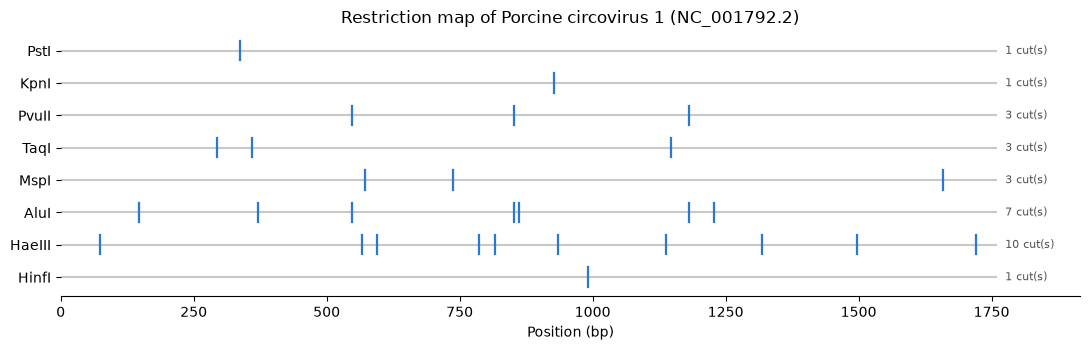

In [5]:
def draw_map(ax, n, result, title):
    names = [k for k, r in result.items() if r["cuts"]]
    for y, name in enumerate(names):
        ax.plot([0, n], [y, y], color="#c9c8c2", lw=1.5, zorder=1)
        for c in result[name]["cuts"]:
            ax.plot([c, c], [y - 0.3, y + 0.3], color="#2a78d6", lw=1.6, zorder=2)
        ax.text(n * 1.01, y, f"{len(result[name]['cuts'])} cut(s)", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(range(len(names)), names)
    ax.set_ylim(len(names) - 0.4, -0.6)
    ax.set_xlim(0, n * 1.09)
    ax.set_xlabel("Position (bp)")
    ax.set_title(title)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)


fig, ax = plt.subplots(figsize=(11, 3.6))
draw_map(ax, len(dna), pcv1, "Restriction map of Porcine circovirus 1 (NC_001792.2)")
plt.tight_layout()
plt.show()

#### Simulation of the electrophoresis gel

The gel has one lane for each restriction enzyme used (plus a DNA ladder in the first lane). As in Lab 5, the distance
travelled by a linear DNA fragment decreases about linearly with the logarithm of its length (long fragments meet more
friction in the gel and move slower):

$$d(N) = L_{gel} \cdot \frac{\log_{10} N_{max} - \log_{10} N}{\log_{10} N_{max} - \log_{10} N_{min}}$$

where $N_{max}$ is a size which practically does not leave the well and $N_{min}$ is the size which just reaches the end of
the gel; smaller fragments run off the gel. All fragments of a digestion come from the same number of molecules, so the
amount of DNA (and the brightness of the band) is proportional to the length of the fragment: small fragments give
faint bands, and fragments of (almost) the same size fall on the same band, which becomes brighter.

Enzymes that do not cut the genome are left out of the gel: an uncut circular molecule does not migrate like a linear
fragment of the same length (supercoiled DNA moves faster), so the model above does not apply to it.

8 enzymes cut PCV1 -> 8 lanes + ladder. Not on the gel (no site): EcoRI, BamHI, HindIII
Smallest fragment = 9 bp


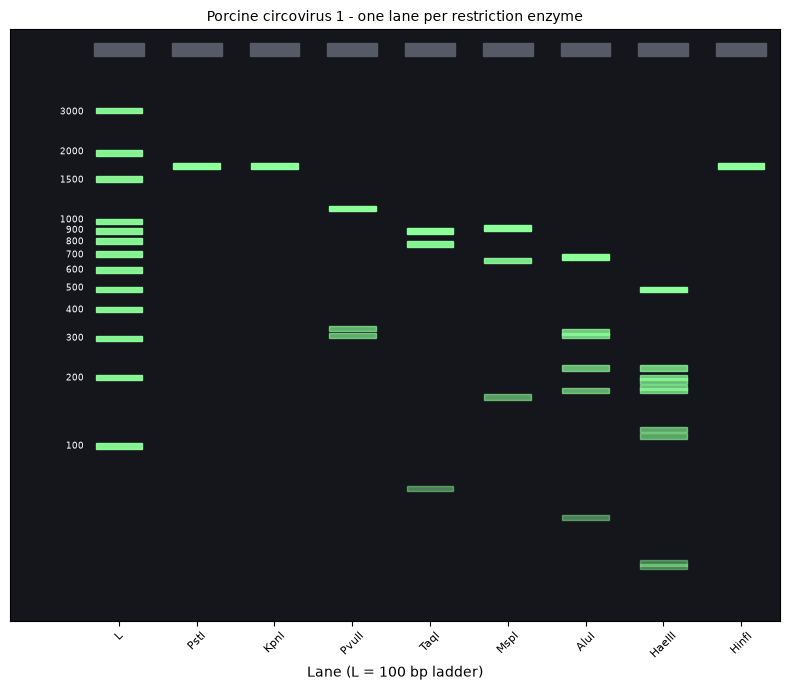

In [6]:
GEL_LENGTH = 10.0  # cm
LADDER_100 = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1500, 2000, 3000]
LADDER_1K = [250, 500, 750, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 5000, 6000, 8000, 10000]


def migration(n_bp, n_min, n_max):
    return GEL_LENGTH * (math.log10(n_max) - math.log10(n_bp)) / (math.log10(n_max) - math.log10(n_min))


def draw_gel(ax, lanes, ladder, n_min, n_max, title, label_ladder=True):
    lanes = [("L", ladder)] + lanes
    ax.set_facecolor("#14161c")
    for x, (label, sizes) in enumerate(lanes):
        ax.add_patch(plt.Rectangle((x - 0.32, -0.35), 0.64, 0.25, color="#555a66"))  # well
        mass = Counter()
        for n in sizes:
            y = migration(n, n_min, n_max)
            if 0 <= y <= GEL_LENGTH:
                mass[round(y / 0.06)] += n
        top = max(mass.values(), default=1) if x else 1
        for yb, m in mass.items():
            a = 0.95 if x == 0 else 0.25 + 0.75 * min(1.0, math.sqrt(m / top))
            ax.add_patch(plt.Rectangle((x - 0.3, yb * 0.06 - 0.05), 0.6, 0.10, color=(0.55, 1.0, 0.6), alpha=a))
    if label_ladder:
        for n in ladder:
            ax.text(-0.45, migration(n, n_min, n_max), f"{n}", color="white", fontsize=6.5, ha="right", va="center")
    ax.set_xlim(-1.4, len(lanes) - 0.5)
    ax.set_ylim(GEL_LENGTH + 0.3, -0.6)
    ax.set_xticks(range(len(lanes)), [l for l, _ in lanes], rotation=45, fontsize=8)
    ax.set_yticks([])
    ax.set_title(title, fontsize=10)


def gel_lanes(result):
    lanes = [(name, [f[2] for f in r["fragments"]]) for name, r in result.items() if r["cuts"]]
    skipped = [name for name, r in result.items() if not r["cuts"]]
    return lanes, skipped


lanes, skipped = gel_lanes(pcv1)
print(f"{len(lanes)} enzymes cut PCV1 -> {len(lanes)} lanes + ladder. Not on the gel (no site): {', '.join(skipped)}")
smallest = min(n for _, sizes in lanes for n in sizes)
print(f"Smallest fragment = {smallest} bp")

fig, ax = plt.subplots(figsize=(8, 7))
draw_gel(ax, lanes, LADDER_100, n_min=20, n_max=5000, title="Porcine circovirus 1 - one lane per restriction enzyme")
ax.set_xlabel("Lane (L = 100 bp ladder)")
plt.tight_layout()
plt.show()

### Exercise 3

Take 2 genome sequences from NCBI and use 3 restriction enzymes (free pattern and cleavage site) for each.

Input: the recognition sequence of each enzyme and the DNA sequence to be digested.
Output: the number of cleavages for each enzyme, the cleavage positions and the length of the fragments, and a
simulation of the electrophoresis gel based on the number of enzymes used.

Genomes used:

| Genome | NCBI | Length | Topology | Enzymes |
|:--|:-:|--:|:-:|:--|
| *Escherichia* phage lambda | NC_001416.1 | 48,502 bp | linear (as in the phage particle) | EcoRI `G^AATTC`, BamHI `G^GATCC`, HindIII `A^AGCTT` |
| *Escherichia* phage phiX174 | NC_001422.1 | 5,386 bp | circular | HaeIII `GG^CC`, HinfI `G^ANTC`, TaqI `T^CGA` |

These two phages were chosen because their digests are sold as DNA size markers (lambda/HindIII, lambda/EcoRI,
phiX174/HaeIII, ...) whose band sizes are well known, so they can be used to check that the program is correct.
The same functions as in Exercise 2 are used - only the input changes.

In [7]:
GENOMES = {
    "lambda": {"file": "lambda.fasta", "circular": False,
               "enzymes": {"EcoRI": "G^AATTC", "BamHI": "G^GATCC", "HindIII": "A^AGCTT"}},
    "phiX174": {"file": "phix174.fasta", "circular": True,
                "enzymes": {"HaeIII": "GG^CC", "HinfI": "G^ANTC", "TaqI": "T^CGA"}},
}

results = {}
for name, g in GENOMES.items():
    header, seq = read_fasta(g["file"])
    g["seq"] = seq
    print("=" * 90)
    print(header)
    results[name] = digest(seq, g["enzymes"], g["circular"])
    report(seq, results[name], g["circular"])
    print()

NC_001416.1 Enterobacteria phage lambda, complete genome
Sequence: 48,502 bp, linear

Enzyme   | Site      | Cleavages | Fragments | Cleavage positions
------------------------------------------------------------------------------------------
EcoRI    | G^AATTC   |         5 |         6 | 21226, 26104, 31747, 39168, 44972
BamHI    | G^GATCC   |         5 |         6 | 5505, 22346, 27972, 34499, 41732
HindIII  | A^AGCTT   |         6 |         7 | 23130, 25157, 27479, 36895, 37459, 44141

EcoRI (G^AATTC) - 5 cleavage(s), 6 fragment(s), largest first:
     # |  Start |    End | Length (bp)
     1 |      1 |  21226 |      21,226
     2 |  31748 |  39168 |       7,421
     3 |  39169 |  44972 |       5,804
     4 |  26105 |  31747 |       5,643
     5 |  21227 |  26104 |       4,878
     6 |  44973 |  48502 |       3,530

BamHI (G^GATCC) - 5 cleavage(s), 6 fragment(s), largest first:
     # |  Start |    End | Length (bp)
     1 |   5506 |  22346 |      16,841
     2 |  34500 |  41732 |   

#### Check against the commercial size markers

The fragment lengths found by the program are compared with the band sizes of the commercial markers:

In [8]:
# commercial markers (bp)
MARKERS = {
    ("lambda", "HindIII"): [23130, 9416, 6557, 4361, 2322, 2027, 564, 125],
    ("lambda", "EcoRI"): [21226, 7421, 5804, 5643, 4878, 3530],
    ("lambda", "BamHI"): [16841, 7233, 6770, 6527, 5626, 5505],
    ("phiX174", "HaeIII"): [1353, 1078, 872, 603, 310, 281, 271, 234, 194, 118, 72],
}

for (genome, enzyme), expected in MARKERS.items():
    found = sorted((f[2] for f in results[genome][enzyme]["fragments"]), reverse=True)
    status = "identical" if found == expected else "DIFFERENT"
    print(f"{genome}/{enzyme:<8} {status}")
    print(f"   program: {found}")
    print(f"   marker : {expected}")

lambda/HindIII  DIFFERENT
   program: [23130, 9416, 6682, 4361, 2322, 2027, 564]
   marker : [23130, 9416, 6557, 4361, 2322, 2027, 564, 125]
lambda/EcoRI    identical
   program: [21226, 7421, 5804, 5643, 4878, 3530]
   marker : [21226, 7421, 5804, 5643, 4878, 3530]
lambda/BamHI    identical
   program: [16841, 7233, 6770, 6527, 5626, 5505]
   marker : [16841, 7233, 6770, 6527, 5626, 5505]
phiX174/HaeIII   identical
   program: [1353, 1078, 872, 603, 310, 281, 271, 234, 194, 118, 72]
   marker : [1353, 1078, 872, 603, 310, 281, 271, 234, 194, 118, 72]


Three of the four digests are identical to the markers. The only difference is lambda/HindIII: the marker has the bands
6557 + 125 where the program finds one band of 6682 = 6557 + 125. The commercial marker is made from the
*lambda cI857 Sam7* strain, which has one extra HindIII site (point mutation) compared with the NCBI reference sequence,
so the program is correct for the sequence it was given.

#### Electrophoresis gels

One gel per genome, with a lane for each of the 3 enzymes. The lambda fragments are large (3.5 - 25 kb), so a 1 kb ladder
and a gel that separates large fragments are used; the phiX174 fragments are small (down to 20 bp) and are run with a 100 bp
ladder.

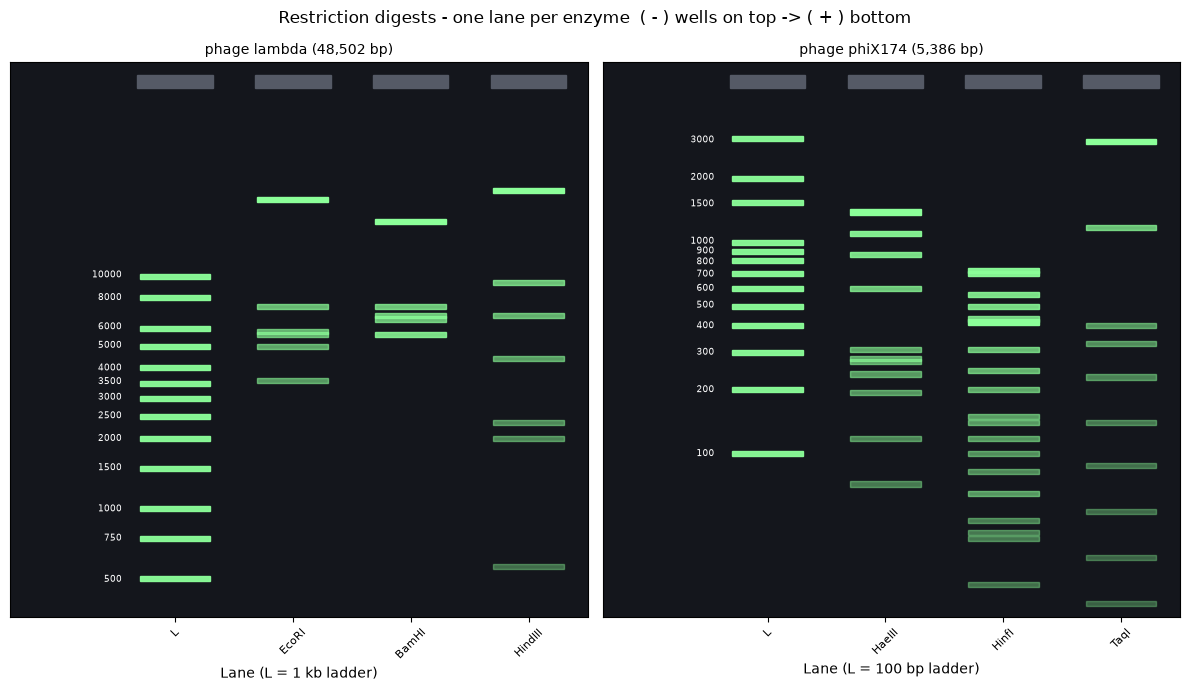

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
gels = [("lambda", LADDER_1K, 400, 60000, "1 kb ladder"), ("phiX174", LADDER_100, 20, 5000, "100 bp ladder")]
for ax, (name, ladder, n_min, n_max, ladder_name) in zip(axes, gels):
    lanes, _ = gel_lanes(results[name])
    draw_gel(ax, lanes, ladder, n_min, n_max, f"phage {name} ({len(GENOMES[name]['seq']):,} bp)")
    ax.set_xlabel(f"Lane (L = {ladder_name})")
fig.suptitle("Restriction digests - one lane per enzyme  ( - ) wells on top -> ( + ) bottom", fontsize=12)
plt.tight_layout()
plt.show()

On the lambda gel every lane shows its 6-7 bands, the ~17-23 kb fragments close to the wells. On the phiX174 gel HinfI
(21 sites) gives many fragments below 750 bp, while TaqI (10 sites, but unevenly spread) leaves one large 2.9 kb fragment
and several below 100 bp. Very close sizes (e.g. 281 and 271 bp of HaeIII, 417 and 413 bp of HinfI) merge into a single,
brighter band, exactly like on a real agarose gel.

### Conclusion

- A restriction enzyme is fully described by its recognition sequence with the cleavage site marked (`G^AATTC`): from it the
  program computes the recognised sequence, the cut on both strands and the type of ends (5' overhang, 3' overhang, blunt).
  IUPAC codes allow degenerate sites such as HinfI `G^ANTC`.
- The digestion searches all (overlapping) occurrences of the site with a regular expression, puts a cut at the cleavage
  offset of every site and splits the molecule into fragments: $k$ cuts give $k+1$ fragments on a linear molecule and $k$
  fragments on a circular one.
- On the 1,758 nt PCV1 genome, 8 of the 11 enzymes cut (from 1 cut for PstI, KpnI and HinfI, which only open the circle,
  up to 10 for HaeIII), while EcoRI, BamHI and HindIII have no site. The 9 bp AluI fragment is too small and runs off the gel.
- On the two phage genomes the fragments are identical to the commercial lambda/EcoRI, lambda/BamHI and phiX174/HaeIII
  markers, and to lambda/HindIII up to the extra site of the strain used for the marker - which validates the program.
- The gel simulation (one lane per enzyme, migration ~ log of the length, brightness ~ length) shows the expected
  patterns: few large fragments for enzymes with 6 bp sites, many small ones for 4-5 bp sites.

### Homework

Digest 2 genomes from 2 versions of the same virus and show the digested segments on separate columns of the same
electrophoresis gel.

Virus used: HIV-1 (human immunodeficiency virus type 1), two classic laboratory strains:

| Version | NCBI | Length | Note |
|:--|:-:|--:|:--|
| HXB2 | K03455.1 | 9,719 bp | the HIV-1 reference genome (all HIV positions are numbered after it) |
| NL4-3 | AF324493.2 | 9,709 bp | an infectious molecular clone, built from two isolates (NY5 and LAV) |

The NL4-3 record on NCBI is the whole plasmid pNL4-3 (14,825 bp): the provirus (positions 1..9709, from the 5' LTR
to the 3' LTR, as written in the record's features) followed by the cloning vector. Only the viral part is digested, so that
the two genomes are compared and not the plasmid. The integrated provirus is a linear molecule.

Both genomes are cut with the same 4 enzymes, and on the gel the two versions are put side by side for every enzyme
(HXB2 | NL4-3), so that any difference between the band patterns is easy to see.

In [10]:
_, hxb2 = read_fasta("hiv_hxb2.fasta")
header_nl43, plasmid = read_fasta("hiv_nl43.fasta")
nl43 = plasmid[:9709]  # only the virus, the rest is the plasmid

VERSIONS = {"HXB2": hxb2, "NL4-3": nl43}
HW_ENZYMES = {"EcoRI": "G^AATTC", "HindIII": "A^AGCTT", "BglII": "A^GATCT", "KpnI": "GGTAC^C"}

print(f"pNL4-3 plasmid: {len(plasmid):,} bp -> provirus used: {len(nl43):,} bp")
print(f"Both versions end with the same 3' LTR: {hxb2[-30:] == nl43[-30:]}\n")

hw = {}
for version, seq in VERSIONS.items():
    print("=" * 90)
    print(f"HIV-1 {version}")
    hw[version] = digest(seq, HW_ENZYMES, circular=False)
    report(seq, hw[version], circular=False)
    print()

pNL4-3 plasmid: 14,825 bp -> provirus used: 9,709 bp
Both versions end with the same 3' LTR: True

HIV-1 HXB2
Sequence: 9,719 bp, linear

Enzyme   | Site      | Cleavages | Fragments | Cleavage positions
------------------------------------------------------------------------------------------
EcoRI    | G^AATTC   |         2 |         3 | 4648, 5743
HindIII  | A^AGCTT   |         6 |         7 | 531, 1085, 1712, 6027, 8141, 9616
BglII    | A^GATCT   |         6 |         7 | 473, 2096, 7041, 7621, 9051, 9558
KpnI     | GGTAC^C   |         4 |         5 | 3830, 4158, 6351, 9019

EcoRI (G^AATTC) - 2 cleavage(s), 3 fragment(s), largest first:
     # |  Start |    End | Length (bp)
     1 |      1 |   4648 |       4,648
     2 |   5744 |   9719 |       3,976
     3 |   4649 |   5743 |       1,095

HindIII (A^AGCTT) - 6 cleavage(s), 7 fragment(s), largest first:
     # |  Start |    End | Length (bp)
     1 |   1713 |   6027 |       4,315
     2 |   6028 |   8141 |       2,114
     3 |   8

#### Comparison of the two versions

For every enzyme: the number of cleavages and the fragments that appear in only one of the two versions. Fragments whose
lengths differ by less than 1% (e.g. 4,315 and 4,314 bp) run to the same place on the gel, so they are counted as a
common band; only the other fragments make a visible difference on the gel.

In [11]:
def compare(frags_a, frags_b, tol=0.01):
    rest_b, common, only_a = sorted(frags_b, reverse=True), [], []
    for n in sorted(frags_a, reverse=True):
        match = next((m for m in rest_b if abs(m - n) <= tol * max(m, n)), None)
        if match is None:
            only_a.append(n)
        else:
            rest_b.remove(match)
            common.append((n, match))
    return common, only_a, rest_b


print(f"{'Enzyme':<8} | {'Cuts HXB2':>9} | {'Cuts NL4-3':>10} | {'Common bands':>12} | {'Only in HXB2':<20} | Only in NL4-3")
print("-" * 95)
for name in HW_ENZYMES:
    fa = [f[2] for f in hw["HXB2"][name]["fragments"]]
    fb = [f[2] for f in hw["NL4-3"][name]["fragments"]]
    common, only_a, only_b = compare(fa, fb)
    print(f"{name:<8} | {len(hw['HXB2'][name]['cuts']):>9} | {len(hw['NL4-3'][name]['cuts']):>10} | {len(common):>12} | "
          f"{str(only_a or '-'):<20} | {only_b or '-'}")

Enzyme   | Cuts HXB2 | Cuts NL4-3 | Common bands | Only in HXB2         | Only in NL4-3
-----------------------------------------------------------------------------------------------
EcoRI    |         2 |          1 |            1 | [4648, 1095]         | [5743]
HindIII  |         6 |          5 |            5 | [627, 554]           | [1181]
BglII    |         6 |          7 |            6 | [1623]               | [1417, 206]
KpnI     |         4 |          4 |            5 | -                    | -


Why the patterns differ. A restriction site is lost or gained when even one base of it changes (a point mutation),
and the fragments shift a little when bases are inserted or deleted between the sites (NL4-3 is 10 bp shorter).

To find these mutations, every site of one version is looked up in the other version:
1. if the other version has the same site within 30 bp of the same position, the site is present in both (the small
   offset comes from insertions/deletions before it);
2. otherwise the 12 bases just before the site (or, if they are mutated too, the 12 bases just after it) are searched
   near the same position in the other genome - they mark the same place - and the bases found there are compared with the
   recognition sequence. The bases that differ are marked with `^`.

In [12]:
def lost_sites(seq_a, seq_b, site, flank=12, window=150, near=30):
    recseq, _ = parse_site(site)
    rx, size = site_regex(recseq), len(recseq)
    sites_b = [m.start() for m in rx.finditer(seq_b)]
    lost = []
    for m in rx.finditer(seq_a):
        s = m.start()
        if any(abs(t - s) <= near for t in sites_b):  # same site in both
            continue
        lo, hi = max(0, s - window), s + window
        j = seq_b.find(seq_a[s - flank:s], lo, hi) if s >= flank else -1
        if j >= 0:
            at = j + flank
        else:
            j = seq_b.find(seq_a[s + size:s + size + flank], lo, hi)  # try the right side
            at = j - size if j >= 0 else None
        lost.append((s + 1, None if at is None else at + 1, None if at is None else seq_b[at:at + size]))
    return lost


def mark(a, b):
    return "".join("^" if x != y else " " for x, y in zip(a, b))


for name, site in HW_ENZYMES.items():
    recseq, _ = parse_site(site)
    found = False
    for (va, sa), (vb, sb) in [(("HXB2", hxb2), ("NL4-3", nl43)), (("NL4-3", nl43), ("HXB2", hxb2))]:
        for pa, pb, bases in lost_sites(sa, sb, site):
            found = True
            if bases is None:
                print(f"{name:<7} site at {va} {pa}: the region around it is too different in {vb}")
            else:
                print(f"{name:<7} {recseq} at {va:<5} {pa:>5}  ->  {vb:<5} {pb:>5} has {bases}   => site only in {va}")
                print(f"{'':<47}{mark(recseq, bases)}")
    if not found:
        print(f"{name:<7} the same sites in both versions (only shifted by the insertions/deletions)")

EcoRI   GAATTC at HXB2   4648  ->  NL4-3  4648 has GCATTC   => site only in HXB2
                                                ^    
HindIII AAGCTT at HXB2   1085  ->  NL4-3  1085 has AAGCCT   => site only in HXB2
                                                   ^ 
BglII   AGATCT at NL4-3   679  ->  HXB2    679 has AGCTCT   => site only in NL4-3
                                                 ^   
KpnI    the same sites in both versions (only shifted by the insertions/deletions)


#### The electrophoresis gel

One gel, one ladder and two columns per enzyme - HXB2 and NL4-3 next to each other.

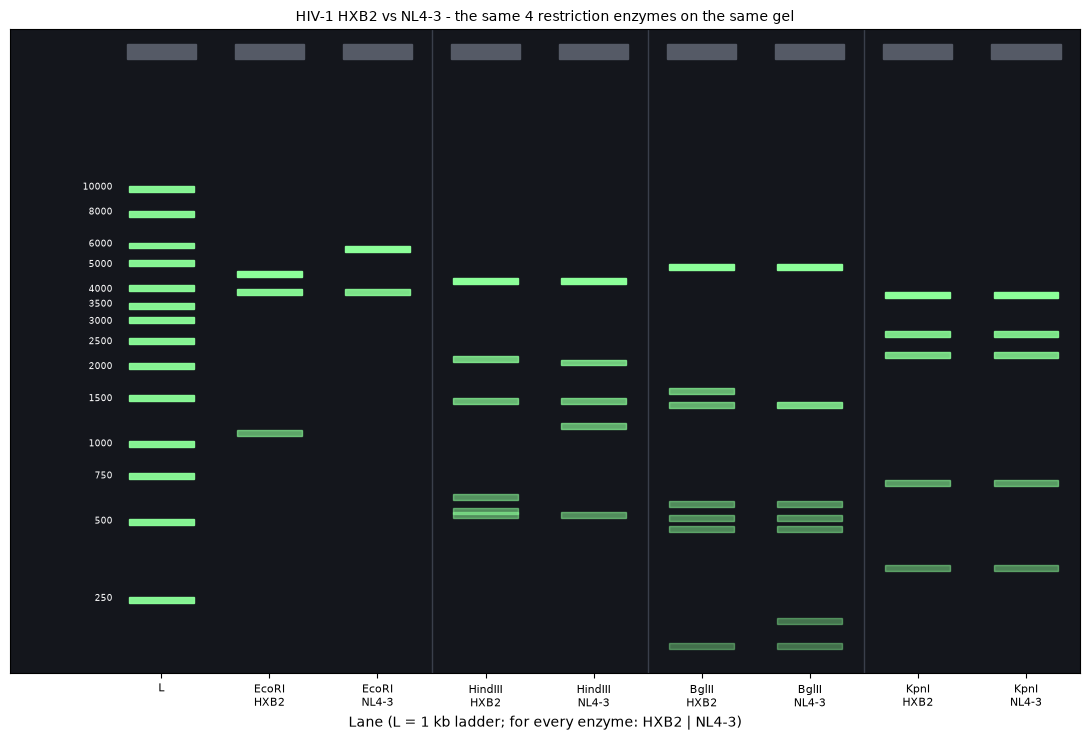

In [13]:
lanes = []
for name in HW_ENZYMES:
    for version in VERSIONS:
        lanes.append((f"{name}\n{version}", [f[2] for f in hw[version][name]["fragments"]]))

fig, ax = plt.subplots(figsize=(11, 7.5))
draw_gel(ax, lanes, LADDER_1K, n_min=150, n_max=30000,
         title="HIV-1 HXB2 vs NL4-3 - the same 4 restriction enzymes on the same gel")
for k in range(1, len(HW_ENZYMES)):
    ax.axvline(2 * k + 0.5, color="#3a3f4b", lw=1)
ax.set_xticks(range(len(lanes) + 1), ["L"] + [l for l, _ in lanes], rotation=0, fontsize=8)
ax.set_xlabel("Lane (L = 1 kb ladder; for every enzyme: HXB2 | NL4-3)")
plt.tight_layout()
plt.show()

#### Homework conclusion

- The two versions of HIV-1 have almost the same genome, so most of the bands are common: KpnI gives the same pattern
  for HXB2 and NL4-3 (the fragments differ by only 4-6 bp, which cannot be seen on the gel).
- Three enzymes show clear differences, each caused by a single point mutation inside a recognition site:
  - EcoRI - HXB2 has a site at 4648 (`GAATTC`), NL4-3 has `GCATTC` there, so in NL4-3 the 4,648 and 1,095 bp
    fragments stay joined into one 5,743 bp fragment (3 bands -> 2 bands);
  - HindIII - HXB2 has a site at 1085 (`AAGCTT`), NL4-3 has `AAGCCT`, so the 554 and 627 bp bands of HXB2 are
    replaced by one 1,181 bp band in NL4-3;
  - BglII - this time NL4-3 has an extra site at 679 (`AGATCT`, HXB2 has `AGCTCT`), so the 1,623 bp band of HXB2 is
    split into 206 + 1,417 bp in NL4-3.
- The small 103 bp HindIII fragment of both versions runs off the end of this gel (it is set up for large fragments).
- This is the principle of RFLP (restriction fragment length polymorphism): digesting two related genomes with the same
  enzymes and running them side by side on one gel shows the mutations that create or destroy restriction sites, without
  reading the whole sequence.